DL PROJECT: Human Activity Recognition Using a 1D CNN

In [1]:
# 1 — Import libraries
import os
import zipfile
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [2]:
#2 — Download the dataset
import os
import urllib.request
import zipfile

# Define the missing path where we want to extract the dataset
extract_path = "./"
zip_filename = "uci_har_dataset.zip"

# URL to the UCI HAR dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00240/UCI%20HAR%20Dataset.zip"

if not os.path.exists(os.path.join(extract_path, "UCI HAR Dataset")):
    print("Downloading dataset...")
    urllib.request.urlretrieve(url, zip_filename)

    print("Extracting dataset...")
    with zipfile.ZipFile(zip_filename, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    # Clean up the downloaded zip file
    os.remove(zip_filename)

data_dir = os.path.join(extract_path, "UCI HAR Dataset")

print("Dataset downloaded successfully!")
print("Dataset path:", data_dir)
print(os.listdir(data_dir))

Extracting dataset...
Dataset downloaded successfully!
Dataset path: ./UCI HAR Dataset
['train', 'activity_labels.txt', 'test', '.DS_Store', 'features_info.txt', 'features.txt', 'README.txt']


In [3]:
#3 — Load the data
signal_names = [
    "total_acc_x", "total_acc_y", "total_acc_z",
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z"
]

def load_signals(split):
    folder = os.path.join(
        data_dir, split, "Inertial Signals"
    )

    signals = []

    for name in signal_names:
        file_path = os.path.join(
            folder, name + "_" + split + ".txt"
        )
        signals.append(np.loadtxt(file_path))

    return np.stack(signals, axis=-1)


X_train = load_signals("train")
X_test = load_signals("test")

y_train = np.loadtxt(
    os.path.join(data_dir, "train", "y_train.txt"),
    dtype=int
) - 1

y_test = np.loadtxt(
    os.path.join(data_dir, "test", "y_test.txt"),
    dtype=int
) - 1

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Data loaded successfully!")

Training data shape: (7352, 128, 9)
Testing data shape: (2947, 128, 9)
Data loaded successfully!


In [4]:
#4 — Display activity names
activity_names = [
    "Walking",
    "Walking Upstairs",
    "Walking Downstairs",
    "Sitting",
    "Standing",
    "Laying"
]

for i, activity in enumerate(activity_names):
    print(i, "-", activity)

0 - Walking
1 - Walking Upstairs
2 - Walking Downstairs
3 - Sitting
4 - Standing
5 - Laying


In [5]:
#5 — Create the CNN model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D,
    GlobalAveragePooling1D, Dense, Dropout
)

model = Sequential([
    Input(shape=(128, 9)),
    Conv1D(64, 5, activation="relu"),
    MaxPooling1D(2),
    Conv1D(128, 3, activation="relu"),
    MaxPooling1D(2),
    GlobalAveragePooling1D(),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(6, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 124, 64)        │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 62, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 60, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,294 (141.77 KB)

 Trainable params: 36,294 (141.77 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
#6 — Train the model
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.6274 - loss: 0.9433 - val_accuracy: 0.7818 - val_loss: 0.5921
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.8619 - loss: 0.3752 - val_accuracy: 0.8980 - val_loss: 0.3262
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.9255 - loss: 0.2099 - val_accuracy: 0.9082 - val_loss: 0.2771
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.9446 - loss: 0.1538 - val_accuracy: 0.9041 - val_loss: 0.2602
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.9512 - loss: 0.1286 - val_accuracy: 0.9171 - val_loss: 0.2622
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.9510 - loss: 0.1181 - val_accuracy: 0.9239 - val_loss: 0.2450
Epoch 7/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.9510 - loss: 0.1148 - val_accuracy: 0.9225 - val_loss: 0.2715
Epoch 8/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.9541 - loss: 0.1102 - val_accuracy: 0.9225 - v

In [7]:
#7 — Calculate accuracy
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Test Loss: 0.3239
Test Accuracy: 89.96 %


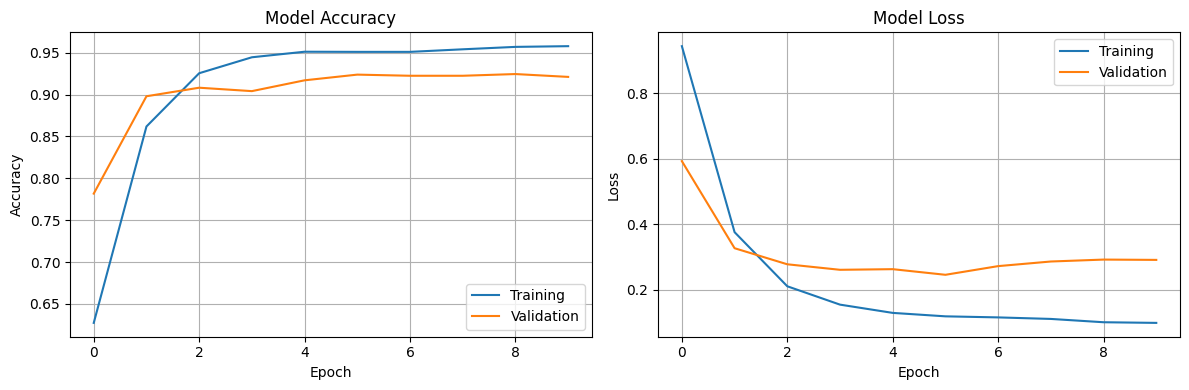

In [8]:
#8 — Display training graphs
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

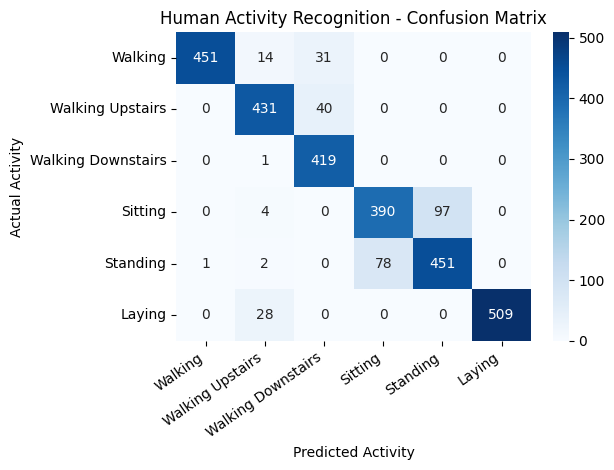

                    precision    recall  f1-score   support

           Walking       1.00      0.91      0.95       496
  Walking Upstairs       0.90      0.92      0.91       471
Walking Downstairs       0.86      1.00      0.92       420
           Sitting       0.83      0.79      0.81       491
          Standing       0.82      0.85      0.84       532
            Laying       1.00      0.95      0.97       537

          accuracy                           0.90      2947
         macro avg       0.90      0.90      0.90      2947
      weighted avg       0.90      0.90      0.90      2947



In [9]:
#9 — Generate the confusion matrix
y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

cm = confusion_matrix(
    y_test, y_pred, labels=np.arange(6)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=activity_names,
    yticklabels=activity_names
)

plt.title("Human Activity Recognition - Confusion Matrix")
plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(6),
    target_names=activity_names,
    zero_division=0
))

In [10]:
#10 — Predict an activity and save the model
sample_index = 0

sample = X_test[sample_index:sample_index + 1]
prediction = model.predict(sample, verbose=0)

predicted_class = np.argmax(prediction, axis=1)[0]
actual_class = y_test[sample_index]

print("Actual Activity:", activity_names[actual_class])
print("Predicted Activity:", activity_names[predicted_class])
print(
    "Prediction Confidence:",
    round(float(np.max(prediction)) * 100, 2),
    "%"
)

model.save("/content/human_activity_cnn.keras")
print("Model saved successfully!")

Actual Activity: Standing
Predicted Activity: Standing
Prediction Confidence: 99.26 %
Model saved successfully!
